# Módulo 30: Descomposición en valores singulares (SVD)

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m30-svd-solucion.ipynb](m30-svd-solucion.ipynb). No es una tarea entregada del programa.

Toda tabla numérica es una **matriz**, y la **descomposición en valores singulares** (SVD) la separa en piezas que revelan sus direcciones principales. Es la herramienta que hay detrás de la reducción de dimensión, de PCA, de la compresión de imágenes y de muchos sistemas de recomendación. En esta lección se aplica a las calificaciones de diez estudiantes:

1. Una matriz como datos
2. La descomposición $X = U\Sigma V^\top$
3. Aproximación de rango k
4. Proyección a k dimensiones
5. Varianza explicada
6. SVD y PCA
7. Interpretar las cargas
8. Errores frecuentes
9. Ejercicio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD

np.set_printoptions(precision=3, suppress=True)

## 1. Una matriz como datos

Una tabla con $n$ registros y $p$ variables es una matriz $X$ de $n \times p$: cada fila es un estudiante y cada columna una materia. La SVD busca direcciones que pasan por el **origen**, así que antes se **centra** cada columna (se le resta su media); si no, la primera dirección solo apunta hacia el promedio de los datos. Si las columnas tuvieran escalas muy distintas, además se **escalaría** cada una a desviación 1, para que ninguna domine.

In [2]:
calificaciones = pd.read_csv("calificaciones-estudiantes.csv", index_col="Nombre")
print(calificaciones)
print("\nMedias:", calificaciones.mean().round(2).to_dict())
print("Desviaciones:", calificaciones.std().round(2).to_dict())

        Matemáticas  Ciencias  Español  Historia  EdFísica
Nombre                                                    
Lucía           7.0       6.5      9.2       8.6       8.0
Pedro           7.5       9.4      7.3       7.0       7.0
Inés            7.6       9.2      8.0       8.0       7.5
Luis            5.0       6.5      6.5       7.0       9.0
Andrés          6.0       6.0      7.8       8.9       7.3
Ana             7.8       9.6      7.7       8.0       6.5
Carlos          6.3       6.4      8.2       9.0       7.2
José            7.9       9.7      7.5       8.0       6.0
Sonia           6.0       6.0      6.5       5.5       8.7
María           6.8       7.2      8.7       9.0       7.0

Medias: {'Matemáticas': 6.79, 'Ciencias': 7.65, 'Español': 7.74, 'Historia': 7.9, 'EdFísica': 7.42}
Desviaciones: {'Matemáticas': 0.95, 'Ciencias': 1.61, 'Español': 0.86, 'Historia': 1.12, 'EdFísica': 0.93}


In [3]:
X = calificaciones.to_numpy()
Xc = X - X.mean(axis=0)                              # centrado
Xs = StandardScaler().fit_transform(calificaciones)  # centrado y escalado
print("Medias de las columnas centradas:", Xc.mean(axis=0).round(10))

Medias de las columnas centradas: [-0. -0. -0. -0.  0.]


Las cinco materias están en la misma escala (0 a 10), pero sus desviaciones van de 0.86 (Español) a 1.61 (Ciencias). En lo que sigue se trabaja con los datos estandarizados `Xs`, para que cada materia pese lo mismo.

## 2. La descomposición $X = U\Sigma V^\top$

Toda matriz real $X$ de $n \times p$ se puede escribir como

$$X = U \Sigma V^\top,$$

| Pieza | Tamaño (forma reducida) | Propiedad |
| --- | --- | --- |
| $U$ | $n \times r$ | Columnas ortonormales: $U^\top U = I$. Coordenadas de los registros |
| $\Sigma$ | $r \times r$ | Diagonal con $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r \ge 0$: los **valores singulares** |
| $V$ | $p \times r$ | Columnas ortonormales: $V^\top V = I$. Direcciones en el espacio de las variables |

con $r = \min(n, p)$. `np.linalg.svd(X, full_matrices=False)` devuelve $U$, el vector de valores singulares y $V^\top$ (no $V$).

In [4]:
U, s, Vt = np.linalg.svd(Xs, full_matrices=False)
print("Formas:", U.shape, s.shape, Vt.shape)
print("Valores singulares:", s)
print("U^T U = I:", np.allclose(U.T @ U, np.eye(len(s))))
print("V^T V = I:", np.allclose(Vt @ Vt.T, np.eye(len(s))))
print("U Σ V^T reconstruye X:", np.allclose(U @ np.diag(s) @ Vt, Xs))

Formas: (10, 5) (5,) (5, 5)
Valores singulares: [5.379 4.036 1.862 1.107 0.298]
U^T U = I: True
V^T V = I: True
U Σ V^T reconstruye X: True


## 3. Aproximación de rango k

La SVD escribe la matriz como suma de $r$ capas de rango 1, ordenadas por importancia:

$$X = \sum_{i=1}^{r} \sigma_i\, u_i v_i^\top.$$

Quedarse con las $k$ primeras da $X_k = U_k \Sigma_k V_k^\top$. El **teorema de Eckart–Young** garantiza que $X_k$ es la mejor aproximación de rango $k$ de $X$ en norma de Frobenius, y que su error es exactamente lo que se descarta:

$$\lVert X - X_k \rVert_F^2 = \sum_{i > k} \sigma_i^2.$$

In [5]:
for k in range(1, 6):
    Xk = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
    error = np.linalg.norm(Xs - Xk, "fro") ** 2
    print(f"k={k}: error={error:7.3f}   suma de σ_i² descartados={np.sum(s[k:] ** 2):7.3f}")

k=1: error= 21.068   suma de σ_i² descartados= 21.068
k=2: error=  4.781   suma de σ_i² descartados=  4.781
k=3: error=  1.315   suma de σ_i² descartados=  1.315
k=4: error=  0.089   suma de σ_i² descartados=  0.089
k=5: error=  0.000   suma de σ_i² descartados=  0.000


## 4. Proyección a k dimensiones

Las coordenadas de los registros en las $k$ primeras direcciones se obtienen proyectando sobre $V_k$, y coinciden con $U_k \Sigma_k$:

$$X V_k = U \Sigma V^\top V_k = U_k \Sigma_k.$$

Esa matriz de $n \times k$ es la versión reducida de los datos, lista para graficar o para usar en otro modelo.

X V_k = U_k Σ_k: True


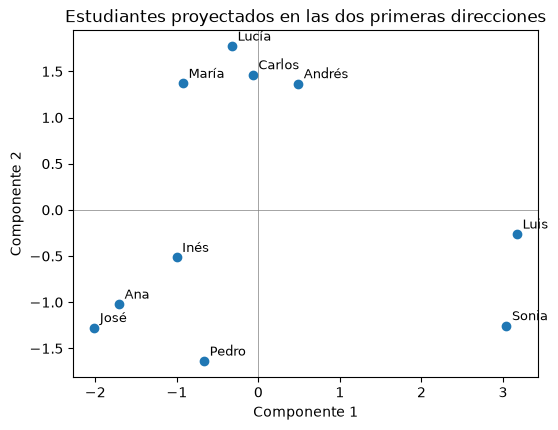

In [6]:
k = 2
proy = Xs @ Vt[:k].T
print("X V_k = U_k Σ_k:", np.allclose(proy, U[:, :k] * s[:k]))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(proy[:, 0], proy[:, 1])
for nombre, (a, b) in zip(calificaciones.index, proy):
    ax.annotate(nombre, (a, b), textcoords="offset points", xytext=(4, 4), fontsize=9)
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.set_title("Estudiantes proyectados en las dos primeras direcciones")
plt.show()

## 5. Varianza explicada

Con datos centrados, la varianza total es $\frac{1}{n-1}\sum_i \sigma_i^2$ y la componente $i$ aporta $\sigma_i^2/(n-1)$. La **proporción de varianza explicada** no depende de $n$:

$$\text{VE}_i = \frac{\sigma_i^2}{\sum_j \sigma_j^2}.$$

La suma acumulada indica cuántas dimensiones hacen falta para conservar, por ejemplo, el 90 % de la información.

        VE  VE acumulada
C1  0.5786        0.5786
C2  0.3257        0.9044
C3  0.0693        0.9737
C4  0.0245        0.9982
C5  0.0018        1.0000


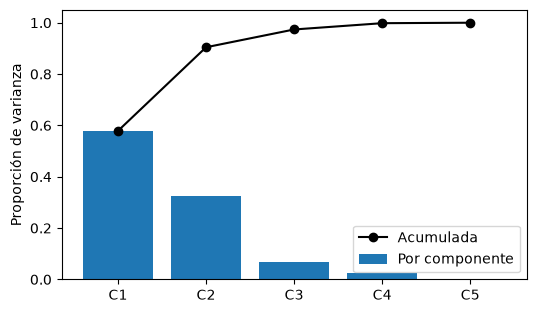

In [7]:
ve = s ** 2 / np.sum(s ** 2)
tabla_ve = pd.DataFrame({"VE": ve, "VE acumulada": ve.cumsum()},
                        index=[f"C{i}" for i in range(1, 6)]).round(4)
print(tabla_ve)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(tabla_ve.index, tabla_ve["VE"], label="Por componente")
ax.plot(tabla_ve.index, tabla_ve["VE acumulada"], marker="o", color="k", label="Acumulada")
ax.set_ylabel("Proporción de varianza")
ax.legend()
plt.show()

## 6. SVD y PCA

PCA busca las direcciones de máxima varianza, que son los vectores propios de la matriz de covarianza $S = \frac{1}{n-1} X_c^\top X_c$. Sustituyendo $X_c = U\Sigma V^\top$:

$$S = \frac{1}{n-1} V \Sigma U^\top U \Sigma V^\top = V\, \frac{\Sigma^2}{n-1}\, V^\top.$$

Es decir, **las direcciones de PCA son las columnas de $V$** y sus varianzas son $\sigma_i^2/(n-1)$. PCA sobre datos centrados y la SVD son el mismo cálculo. Se comprueba numéricamente; los signos pueden salir invertidos, porque $u_i v_i^\top = (-u_i)(-v_i)^\top$, así que se comparan valores absolutos.

In [8]:
pca = PCA(n_components=5).fit(Xs)
proy_pca = pca.transform(Xs)
proy_svd = U * s

print("Mismas proyecciones (salvo signo):", np.allclose(np.abs(proy_pca), np.abs(proy_svd)))
print("Misma varianza explicada:         ", np.allclose(pca.explained_variance_ratio_, ve))
print("Mismas direcciones (salvo signo): ", np.allclose(np.abs(pca.components_), np.abs(Vt)))
print("Varianzas σ²/(n-1):", (s ** 2 / (len(Xs) - 1)).round(4))
print("pca.explained_variance_:", pca.explained_variance_.round(4))

Mismas proyecciones (salvo signo): True
Misma varianza explicada:          True
Mismas direcciones (salvo signo):  True
Varianzas σ²/(n-1): [3.215 1.81  0.385 0.136 0.01 ]
pca.explained_variance_: [3.215 1.81  0.385 0.136 0.01 ]


## 7. Interpretar las cargas

Cada fila de `pca.components_` (o de $V^\top$) contiene las **cargas** de una componente: el peso de cada variable original en esa dirección. Las cargas grandes en valor absoluto indican qué variables definen la componente, y el signo indica si se mueven juntas o en sentidos opuestos.

In [9]:
cargas = pd.DataFrame(pca.components_[:2], columns=calificaciones.columns,
                      index=["C1", "C2"]).round(3)
cargas

,Matemáticas,Ciencias,Español,Historia,EdFísica
C1,-0.527,-0.425,-0.359,-0.353,0.537
C2,-0.270,-0.508,0.562,0.586,0.094


En la primera componente, las cuatro materias académicas tienen cargas negativas (las mayores, Matemáticas y Ciencias) y Educación Física una positiva de tamaño parecido: opone el rendimiento académico al de Educación Física. En la segunda, Español e Historia tienen cargas positivas grandes y Ciencias y Matemáticas negativas: separa a los estudiantes de humanidades de los de ciencias. Con dos componentes se conserva el 90.4 % de la varianza. El signo global de cada componente es arbitrario; lo que importa son los signos relativos dentro de la misma fila.

## 8. Errores frecuentes

**Aplicar `TruncatedSVD` sin centrar y llamarlo PCA.** `TruncatedSVD` no resta la media (está pensada para matrices dispersas). Sobre los datos crudos, su primera componente apunta hacia el promedio de las calificaciones y no hacia la dirección de máxima variación:

In [10]:
tsvd_crudo = TruncatedSVD(n_components=2, random_state=42).fit(X)
tsvd_centrado = TruncatedSVD(n_components=2, random_state=42).fit(Xc)
pca_centrado = PCA(n_components=2).fit(X)       # PCA centra internamente

print("Primera dirección, TruncatedSVD sin centrar:", tsvd_crudo.components_[0])
print("Dirección de la media normalizada:          ", X.mean(axis=0) / np.linalg.norm(X.mean(axis=0)))
print("TruncatedSVD centrado = PCA:", np.allclose(np.abs(tsvd_centrado.components_),
                                                 np.abs(pca_centrado.components_)))

Primera dirección, TruncatedSVD sin centrar: [0.406 0.458 0.461 0.471 0.438]
Dirección de la media normalizada:           [0.404 0.456 0.461 0.47  0.442]
TruncatedSVD centrado = PCA: True


**Comparar componentes sin considerar el signo.** Dos librerías, o dos versiones de la misma, pueden devolver $v_i$ o $-v_i$. Comparar con `==` o con `np.allclose` sin valor absoluto da un falso "son distintas":

In [11]:
print("Sin valor absoluto:", np.allclose(pca.components_, Vt))
print("Con valor absoluto:", np.allclose(np.abs(pca.components_), np.abs(Vt)))

Sin valor absoluto: False
Con valor absoluto: True


**Olvidar que escalar cambia el resultado.** Centrar y estandarizar no dan las mismas componentes cuando las varianzas de las columnas difieren. Con solo centrar, las materias con más dispersión pesan más:

In [12]:
VE_centrado = PCA().fit(Xc).explained_variance_ratio_
VE_estandar = PCA().fit(Xs).explained_variance_ratio_
print("VE con datos centrados:     ", VE_centrado.round(3))
print("VE con datos estandarizados:", VE_estandar.round(3))

VE con datos centrados:      [0.611 0.313 0.047 0.026 0.001]
VE con datos estandarizados: [0.579 0.326 0.069 0.025 0.002]


## 9. Ejercicio

Usa `load_iris` de scikit-learn (150 flores, 4 medidas).

1. Estandariza las medidas y calcula la SVD con `np.linalg.svd`.
2. Calcula la varianza explicada por componente y la acumulada. ¿Cuántas componentes conservan al menos el 95 %?
3. Construye la aproximación de rango 2 y comprueba el teorema de Eckart–Young.
4. Verifica que las proyecciones $U_2\Sigma_2$ coinciden, salvo signo, con las de `PCA(n_components=2)`.
5. Muestra las cargas de la primera componente e interprétalas.

### Solución

In [13]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).data
Z = StandardScaler().fit_transform(iris)

# 1. SVD
U_i, s_i, Vt_i = np.linalg.svd(Z, full_matrices=False)

# 2. Varianza explicada
ve_i = s_i ** 2 / np.sum(s_i ** 2)
print("VE:", ve_i.round(4), " acumulada:", ve_i.cumsum().round(4))
print("Componentes para el 95 %:", int(np.argmax(ve_i.cumsum() >= 0.95)) + 1)

# 3. Rango 2 y Eckart–Young
Z2 = U_i[:, :2] @ np.diag(s_i[:2]) @ Vt_i[:2]
print("Error de rango 2:", round(np.linalg.norm(Z - Z2, "fro") ** 2, 4),
      " σ3² + σ4²:", round(np.sum(s_i[2:] ** 2), 4))

# 4. Comparación con PCA
p2 = PCA(n_components=2).fit_transform(Z)
print("Proyecciones iguales salvo signo:", np.allclose(np.abs(p2), np.abs(U_i[:, :2] * s_i[:2])))

# 5. Cargas de la primera componente
print(pd.Series(Vt_i[0], index=iris.columns).round(3))

VE: [0.73  0.229 0.037 0.005]  acumulada: [0.73  0.958 0.995 1.   ]
Componentes para el 95 %: 2
Error de rango 2: 25.1208  σ3² + σ4²: 25.1208
Proyecciones iguales salvo signo: True
sepal length (cm)    0.521
sepal width (cm)    -0.269
petal length (cm)    0.580
petal width (cm)     0.565
dtype: float64


Las dos primeras componentes conservan el 95.8 % de la varianza. En la primera, las dos medidas del pétalo y el largo del sépalo tienen cargas grandes del mismo signo, y el ancho del sépalo pesa poco y con signo opuesto: la primera componente resume el **tamaño** de la flor, sobre todo de su pétalo.

## Resumen

- Toda matriz se descompone como $X = U\Sigma V^\top$, con $U$ y $V$ ortonormales y valores singulares ordenados de mayor a menor.
- Conservar las $k$ primeras capas da la mejor aproximación de rango $k$ (Eckart–Young), con error $\sum_{i>k}\sigma_i^2$.
- La proyección $XV_k = U_k\Sigma_k$ reduce los datos a $k$ dimensiones, y $\sigma_i^2/\sum_j\sigma_j^2$ mide la varianza que conserva cada componente.
- Sobre datos centrados, SVD y PCA coinciden: mismas direcciones y proyecciones (salvo signo) y misma varianza explicada.
- `TruncatedSVD` no centra: sin centrar antes, no equivale a PCA.
- Las cargas de `components_` indican qué variables definen cada componente.

En el **Módulo 31** se agrupan registros con el método de los k vecinos más cercanos y se buscan patrones de consumo con el análisis de canasta de mercado.